In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/processed/features.csv", index_col="time", parse_dates=True)

TARGET = "target_pm25_24h"
FEATURES = [c for c in df.columns if c not in [TARGET, "blh"]]

print("Number of features:", len(FEATURES))

Number of features: 39


In [2]:
split_date = "2025-07-01"

train = df[df.index < split_date]
test = df[df.index >= split_date]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print("Train:", train.index.min().date(), "→", train.index.max().date(), f"({len(train)} rows)")
print("Test: ", test.index.min().date(), "→", test.index.max().date(), f"({len(test)} rows)")

Train: 2024-01-03 → 2025-06-30 (11304 rows)
Test:  2025-07-01 → 2025-12-30 (4000 rows)


In [3]:
results = []

def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    results.append({"Model": name, "MAE": round(mae, 1), "RMSE": round(rmse, 1), "R²": round(r2, 3)})
    print(f"{name:30s} MAE={mae:6.1f}  RMSE={rmse:6.1f}  R²={r2:.3f}")

# Baseline 1: PM2.5 in 24 hours = PM2.5 right now
evaluate("Baseline: same as now", y_test, X_test["pm25"])

# Baseline 2: PM2.5 in 24 hours = average of last 24 hours
evaluate("Baseline: last 24h average", y_test, X_test["pm25_mean_24h"])

Baseline: same as now          MAE=  23.4  RMSE=  49.7  R²=0.451
Baseline: last 24h average     MAE=  23.9  RMSE=  46.2  R²=0.525


In [4]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate("Linear Regression", y_test, lr.predict(X_test))

Linear Regression              MAE=  28.3  RMSE=  46.4  R²=0.521


In [5]:
from sklearn.ensemble import HistGradientBoostingRegressor

gb = HistGradientBoostingRegressor(
    max_iter=500,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42,
)
gb.fit(X_train, y_train)
evaluate("Gradient Boosting", y_test, gb.predict(X_test))

Gradient Boosting              MAE=  33.5  RMSE=  52.6  R²=0.385


In [6]:
pd.DataFrame(results)

,Model,MAE,RMSE,R²
0,Baseline: same as now,23.4,49.7,0.451
1,Baseline: last 24h average,23.9,46.2,0.525
2,Linear Regression,28.3,46.4,0.521
3,Gradient Boosting,33.5,52.6,0.385


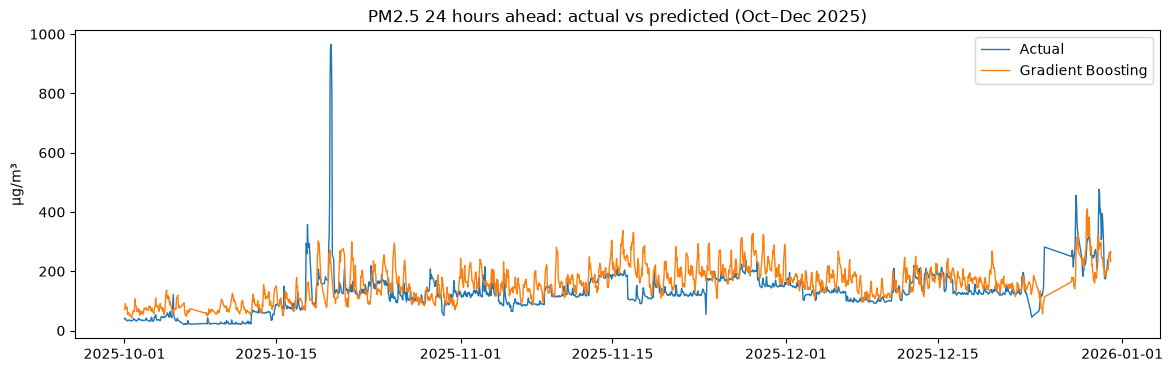

In [7]:
import matplotlib.pyplot as plt

window = test.loc["2025-10-01":"2025-12-31"]

plt.figure(figsize=(14, 4))
plt.plot(window.index, window[TARGET], label="Actual", linewidth=1)
plt.plot(window.index, gb.predict(window[FEATURES]), label="Gradient Boosting", linewidth=1)
plt.title("PM2.5 24 hours ahead: actual vs predicted (Oct–Dec 2025)")
plt.ylabel("µg/m³")
plt.legend()
plt.show()

In [8]:
for name, model in [("Linear Regression", lr), ("Gradient Boosting", gb)]:
    bias = (model.predict(X_test) - y_test).mean()
    print(f"{name}: predicts {bias:+.1f} µg/m³ too high on average")

Linear Regression: predicts +12.2 µg/m³ too high on average
Gradient Boosting: predicts +17.0 µg/m³ too high on average


In [9]:
full = pd.read_csv("../data/processed/merged.csv", index_col="time", parse_dates=True)

monthly = full["pm25"].groupby([full.index.year, full.index.month]).agg(["mean", "std"]).round(0)
monthly.index.names = ["year", "month"]
monthly.unstack("year")

mean           std      
year    2024   2025   2024  2025
month                           
1      217.0  143.0   88.0  83.0
2      105.0   81.0   52.0  42.0
3      100.0   78.0   43.0  44.0
4      116.0  119.0   68.0  96.0
5      161.0   77.0  115.0  61.0
6      141.0   64.0  130.0  34.0
7       35.0   44.0   22.0  20.0
8       47.0   51.0   18.0  42.0
9       60.0   56.0   41.0  24.0
10     100.0   91.0   68.0  90.0
11     268.0  138.0  118.0  35.0
12     166.0  164.0   79.0  80.0

In [10]:
stuck = (full["pm25"].diff() == 0)
print("% of hours where PM2.5 didn't change at all from the previous hour, by month:")
(stuck.groupby(full.index.to_period("M")).mean() * 100).round(0)

% of hours where PM2.5 didn't change at all from the previous hour, by month:


time
2024-01    0.0
2024-02    0.0
2024-03    0.0
2024-04    0.0
2024-05    0.0
2024-06    1.0
2024-07    0.0
2024-08    0.0
2024-09    0.0
2024-10    0.0
2024-11    0.0
2024-12    0.0
2025-01    0.0
2025-02    0.0
2025-03    0.0
2025-04    0.0
2025-05    0.0
2025-06    0.0
2025-07    0.0
2025-08    0.0
2025-09    0.0
2025-10    1.0
2025-11    0.0
2025-12    1.0
Freq: M, Name: pm25, dtype: float64

In [11]:
# Instead of "what will PM2.5 be?", ask "how much will it go up or down?"
y_train_change = y_train - X_train["pm25"]

gb_change = HistGradientBoostingRegressor(
    max_iter=500, learning_rate=0.05, max_leaf_nodes=31, random_state=42
)
gb_change.fit(X_train, y_train_change)
evaluate("GB (predicts change)", y_test, X_test["pm25"] + gb_change.predict(X_test))

lr_change = LinearRegression().fit(X_train, y_train_change)
evaluate("LR (predicts change)", y_test, X_test["pm25"] + lr_change.predict(X_test))

pd.DataFrame(results)

GB (predicts change)           MAE=  32.2  RMSE=  52.2  R²=0.395
LR (predicts change)           MAE=  28.3  RMSE=  46.4  R²=0.521


,Model,MAE,RMSE,R²
0,Baseline: same as now,23.4,49.7,0.451
1,Baseline: last 24h average,23.9,46.2,0.525
2,Linear Regression,28.3,46.4,0.521
3,Gradient Boosting,33.5,52.6,0.385
4,GB (predicts change),32.2,52.2,0.395
5,LR (predicts change),28.3,46.4,0.521


In [12]:
wx = pd.read_csv("../data/raw/weather.csv", skiprows=3, index_col="time", parse_dates=True)
wx = wx.rename(columns={
    "temperature_2m (°C)": "temp",
    "relative_humidity_2m (%)": "humidity",
    "dew_point_2m (°C)": "dew_point",
    "precipitation (mm)": "rain",
    "wind_speed_10m (km/h)": "wind_speed",
    "wind_direction_10m (°)": "wind_dir",
    "surface_pressure (hPa)": "pressure",
    "cloud_cover (%)": "cloud",
}).asfreq("h")

rad = np.deg2rad(wx["wind_dir"])
fut = pd.DataFrame(index=wx.index)
for col in ["temp", "humidity", "dew_point", "wind_speed", "pressure", "cloud"]:
    fut[f"{col}_next24"] = wx[col].shift(-24)
fut["wind_u_next24"] = (wx["wind_speed"] * np.sin(rad)).shift(-24)
fut["wind_v_next24"] = (wx["wind_speed"] * np.cos(rad)).shift(-24)
fut["rain_sum_next24"] = wx["rain"].rolling(24).sum().shift(-24)  # total rain over the next 24 hours

df2 = df.join(fut).dropna(subset=fut.columns)
FEATURES2 = FEATURES + list(fut.columns)

train2, test2 = df2[df2.index < split_date], df2[df2.index >= split_date]
X_train2, y_train2 = train2[FEATURES2], train2[TARGET]
X_test2, y_test2 = test2[FEATURES2], test2[TARGET]
print("Features now:", len(FEATURES2))

Features now: 48


In [13]:
lr2 = LinearRegression().fit(X_train2, y_train2)
evaluate("LR + tomorrow's weather", y_test2, lr2.predict(X_test2))

gb2 = HistGradientBoostingRegressor(
    loss="absolute_error",
    max_iter=500, learning_rate=0.05, max_leaf_nodes=31, random_state=42,
)
gb2.fit(X_train2, y_train2)
evaluate("GB + tomorrow's weather", y_test2, gb2.predict(X_test2))

LR + tomorrow's weather        MAE=  28.0  RMSE=  46.0  R²=0.529
GB + tomorrow's weather        MAE=  26.2  RMSE=  45.6  R²=0.538


In [14]:
preds = []
for month_start in pd.date_range("2025-07-01", "2025-12-01", freq="MS"):
    month_end = month_start + pd.offsets.MonthBegin(1)

    # Train only on rows whose 24h-ahead answer was already known before this month
    tr = df2[df2.index < month_start - pd.Timedelta(hours=24)]
    te = df2[(df2.index >= month_start) & (df2.index < month_end)]

    m = HistGradientBoostingRegressor(
        loss="absolute_error", max_iter=500, learning_rate=0.05,
        max_leaf_nodes=31, random_state=42,
    ).fit(tr[FEATURES2], tr[TARGET])
    preds.append(pd.Series(m.predict(te[FEATURES2]), index=te.index))

wf = pd.concat(preds)
evaluate("GB walk-forward (monthly retrain)", y_test2.loc[wf.index], wf)

pd.DataFrame(results)

GB walk-forward (monthly retrain) MAE=  24.3  RMSE=  44.1  R²=0.568


,Model,MAE,RMSE,R²
0,Baseline: same as now,23.4,49.7,0.451
1,Baseline: last 24h average,23.9,46.2,0.525
2,Linear Regression,28.3,46.4,0.521
3,Gradient Boosting,33.5,52.6,0.385
4,GB (predicts change),32.2,52.2,0.395
5,LR (predicts change),28.3,46.4,0.521
6,LR + tomorrow's weather,28.0,46.0,0.529
7,GB + tomorrow's weather,26.2,45.6,0.538
8,GB walk-forward (monthly retrain),24.3,44.1,0.568


In [15]:
def walk_forward(log_target=False):
    preds = []
    for month_start in pd.date_range("2025-07-01", "2025-12-01", freq="MS"):
        month_end = month_start + pd.offsets.MonthBegin(1)
        tr = df2[df2.index < month_start - pd.Timedelta(hours=24)]
        te = df2[(df2.index >= month_start) & (df2.index < month_end)]

        y = np.log1p(tr[TARGET]) if log_target else tr[TARGET]
        m = HistGradientBoostingRegressor(
            loss="absolute_error", max_iter=500, learning_rate=0.05,
            max_leaf_nodes=31, random_state=42,
        ).fit(tr[FEATURES2], y)

        p = m.predict(te[FEATURES2])
        preds.append(pd.Series(np.expm1(p) if log_target else p, index=te.index))
    return pd.concat(preds)

wf_log = walk_forward(log_target=True)

# Score everything on the exact same hours
rows = wf.index
y_true = y_test2.loc[rows]
results = []

evaluate("Baseline: same as now", y_true, X_test2.loc[rows, "pm25"])
evaluate("Baseline: last 24h average", y_true, X_test2.loc[rows, "pm25_mean_24h"])
evaluate("GB + weather (trained once)", y_true, pd.Series(gb2.predict(X_test2), index=X_test2.index).loc[rows])
evaluate("GB walk-forward", y_true, wf)
evaluate("GB walk-forward (log target)", y_true, wf_log.loc[rows])

final_table = pd.DataFrame(results)
final_table

Baseline: same as now          MAE=  23.4  RMSE=  49.7  R²=0.451
Baseline: last 24h average     MAE=  23.9  RMSE=  46.2  R²=0.525
GB + weather (trained once)    MAE=  26.2  RMSE=  45.6  R²=0.538
GB walk-forward                MAE=  24.3  RMSE=  44.1  R²=0.568
GB walk-forward (log target)   MAE=  24.2  RMSE=  44.7  R²=0.556


,Model,MAE,RMSE,R²
0,Baseline: same as now,23.4,49.7,0.451
1,Baseline: last 24h average,23.9,46.2,0.525
2,GB + weather (trained once),26.2,45.6,0.538
3,GB walk-forward,24.3,44.1,0.568
4,GB walk-forward (log target),24.2,44.7,0.556


In [17]:
import os
os.makedirs("../reports", exist_ok=True)
final_table.to_csv("../reports/evaluation_table.csv", index=False)
print(final_table.to_markdown(index=False))

| Model                        |   MAE |   RMSE |    R² |
|:-----------------------------|------:|-------:|------:|
| Baseline: same as now        |  23.4 |   49.7 | 0.451 |
| Baseline: last 24h average   |  23.9 |   46.2 | 0.525 |
| GB + weather (trained once)  |  26.2 |   45.6 | 0.538 |
| GB walk-forward              |  24.3 |   44.1 | 0.568 |
| GB walk-forward (log target) |  24.2 |   44.7 | 0.556 |


In [18]:
def pm25_category(v):
    # India's National AQI breakpoints for 24-hour PM2.5 (µg/m³)
    if v <= 30:  return "Good"
    if v <= 60:  return "Satisfactory"
    if v <= 90:  return "Moderate"
    if v <= 120: return "Poor"
    if v <= 250: return "Very Poor"
    return "Severe"

actual_cat = y_true.apply(pm25_category)

for name, pred in [("Baseline: same as now", X_test2.loc[rows, "pm25"]), ("GB walk-forward", wf)]:
    acc = (pred.apply(pm25_category) == actual_cat).mean()
    print(f"{name:25s} category accuracy: {acc:.1%}")

Baseline: same as now     category accuracy: 59.0%
GB walk-forward           category accuracy: 58.1%


In [19]:
import joblib

# The final model learns from every row whose answer is known
final_model = HistGradientBoostingRegressor(
    loss="absolute_error", max_iter=500, learning_rate=0.05,
    max_leaf_nodes=31, random_state=42,
).fit(df2[FEATURES2], df2[TARGET])

os.makedirs("../models", exist_ok=True)
joblib.dump(
    {
        "model": final_model,
        "features": FEATURES2,
        "trained_until": str(df2.index.max()),
    },
    "../models/aqi_model.joblib",
)
print("Model saved! Trained on data up to", df2.index.max())

Model saved! Trained on data up to 2025-12-30 23:00:00


In [20]:
out = pd.DataFrame({
    "actual": y_true.values,
    "predicted": wf.values,
    "baseline": X_test2.loc[rows, "pm25"].values,
}, index=rows + pd.Timedelta(hours=24))   # label each row by the hour being forecast
out.index.name = "forecast_for"

out.to_csv("../reports/test_predictions.csv")
print("Saved", len(out), "rows")

Saved 4000 rows
